In [1]:
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn import metrics

sns.set_style("whitegrid")

In [2]:
path = glob.glob("/kaggle/input/**/smoke_detection_iot.csv", recursive=True)[0]
df = pd.read_csv(path)
print("Shape:", df.shape)
df.head()

Shape: (62630, 16)


,Unnamed: 0,UTC,Temperature[C],Humidity[%],TVOC[ppb],eCO2[ppm],Raw H2,Raw Ethanol,Pressure[hPa],PM1.0,PM2.5,NC0.5,NC1.0,NC2.5,CNT,Fire Alarm
0,0,1654733331,20.000,57.36,0,400,12306,18520,939.735,0.0,0.0,0.0,0.0,0.0,0,0
1,1,1654733332,20.015,56.67,0,400,12345,18651,939.744,0.0,0.0,0.0,0.0,0.0,1,0
2,2,1654733333,20.029,55.96,0,400,12374,18764,939.738,0.0,0.0,0.0,0.0,0.0,2,0
3,3,1654733334,20.044,55.28,0,400,12390,18849,939.736,0.0,0.0,0.0,0.0,0.0,3,0
4,4,1654733335,20.059,54.69,0,400,12403,18921,939.744,0.0,0.0,0.0,0.0,0.0,4,0


In [3]:
df.info()
print(df.isnull().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 62630 entries, 0 to 62629
Data columns (total 16 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Unnamed: 0      62630 non-null  int64  
 1   UTC             62630 non-null  int64  
 2   Temperature[C]  62630 non-null  float64
 3   Humidity[%]     62630 non-null  float64
 4   TVOC[ppb]       62630 non-null  int64  
 5   eCO2[ppm]       62630 non-null  int64  
 6   Raw H2          62630 non-null  int64  
 7   Raw Ethanol     62630 non-null  int64  
 8   Pressure[hPa]   62630 non-null  float64
 9   PM1.0           62630 non-null  float64
 10  PM2.5           62630 non-null  float64
 11  NC0.5           62630 non-null  float64
 12  NC1.0           62630 non-null  float64
 13  NC2.5           62630 non-null  float64
 14  CNT             62630 non-null  int64  
 15  Fire Alarm      62630 non-null  int64  
dtypes: float64(8), int64(8)
memory usage: 7.6 MB
Unnamed: 0        0
UTC        

Rows removed: 0
Fire Alarm
1    0.714626
0    0.285374
Name: proportion, dtype: float64


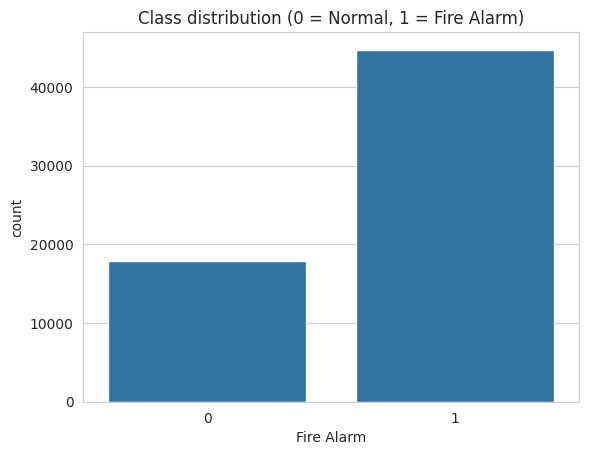

In [4]:
before = len(df)
df = df.dropna().drop_duplicates()
print(f"Rows removed: {before - len(df)}")

print(df["Fire Alarm"].value_counts(normalize=True))
sns.countplot(x="Fire Alarm", data=df)
plt.title("Class distribution (0 = Normal, 1 = Fire Alarm)")
plt.show()

In [5]:
target = "Fire Alarm"
drop_cols = [c for c in ["Unnamed: 0", "UTC", "CNT"] if c in df.columns]

X = df.drop(columns=drop_cols + [target])
y = df[target]

# Train/Test split 80/20 مع الحفاظ على نسبة الفئات
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print(X_train.shape, X_test.shape)

(50104, 12) (12526, 12)


In [6]:
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, cross_validate

# 5-Fold Cross-Validation مع الحفاظ على نسب الفئات في كل fold
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = ["accuracy", "precision", "recall", "f1"]

def cv_report(name, model, X, y):
    cv = cross_validate(model, X, y, cv=skf, scoring=scoring)
    print(f"--- {name}: 5-Fold CV (mean ± std) ---")
    for m in scoring:
        s = cv[f"test_{m}"]
        print(f"{m:10s}: {s.mean():.4f} ± {s.std():.4f}")

# Pipeline: التطبيع ثم الموديل، و class_weight لموازنة الفئات
lr_pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", LogisticRegression(max_iter=1000, class_weight="balanced",
                               random_state=42)),
])

cv_report("Logistic Regression", lr_pipe, X_train, y_train)

# التدريب النهائي على كامل Train، ثم التنبؤ على Test
lr_pipe.fit(X_train, y_train)
y_pred_lr = lr_pipe.predict(X_test)

--- Logistic Regression: 5-Fold CV (mean ± std) ---
accuracy  : 0.9054 ± 0.0021
precision : 0.9648 ± 0.0029
recall    : 0.9005 ± 0.0031
f1        : 0.9315 ± 0.0016


--- Logistic Regression ---
Accuracy  : 0.9009
Precision : 0.9660
Recall    : 0.8927
F1-Score  : 0.9279


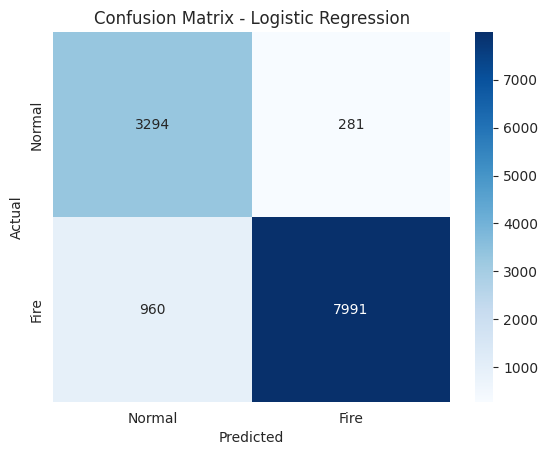

TN=3294  FP=281  FN=960  TP=7991


In [7]:
def evaluate(name, y_true, y_pred):
    res = {
        "Model": name,
        "Accuracy":  metrics.accuracy_score(y_true, y_pred),
        "Precision": metrics.precision_score(y_true, y_pred),
        "Recall":    metrics.recall_score(y_true, y_pred),
        "F1-Score":  metrics.f1_score(y_true, y_pred),
    }
    print(f"--- {name} ---")
    for k, v in res.items():
        if k != "Model":
            print(f"{k:10s}: {v:.4f}")
    return res

def plot_cm(y_true, y_pred, title):
    cm = metrics.confusion_matrix(y_true, y_pred)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=["Normal", "Fire"], yticklabels=["Normal", "Fire"])
    plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.title(title)
    plt.show()
    tn, fp, fn, tp = cm.ravel()
    print(f"TN={tn}  FP={fp}  FN={fn}  TP={tp}")

res_lr = evaluate("Logistic Regression", y_test, y_pred_lr)
plot_cm(y_test, y_pred_lr, "Confusion Matrix - Logistic Regression")

scale_pos_weight = 0.399
--- XGBoost: 5-Fold CV (mean ± std) ---
accuracy  : 0.9999 ± 0.0001
precision : 0.9999 ± 0.0001
recall    : 0.9999 ± 0.0001
f1        : 0.9999 ± 0.0001
--- XGBoost ---
Accuracy  : 0.9999
Precision : 1.0000
Recall    : 0.9999
F1-Score  : 0.9999


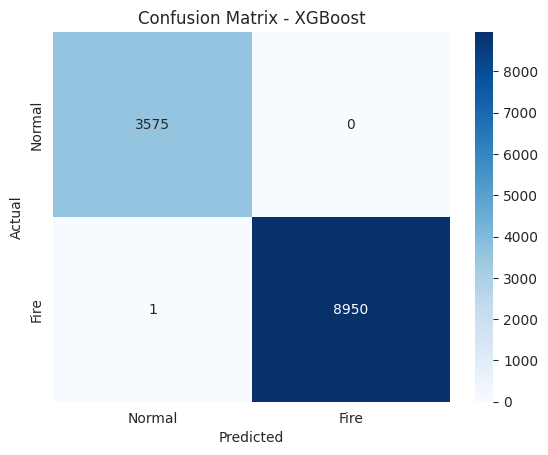

TN=3575  FP=0  FN=1  TP=8950


In [8]:
from xgboost import XGBClassifier

# موازنة الفئات في XGBoost: نسبة الفئة السالبة إلى الموجبة
spw = (y_train == 0).sum() / (y_train == 1).sum()
print("scale_pos_weight =", round(spw, 3))

xgb = XGBClassifier(n_estimators=200, max_depth=4, learning_rate=0.1,
                    scale_pos_weight=spw, eval_metric="logloss",
                    random_state=42)

cv_report("XGBoost", xgb, X_train.values, y_train)

xgb.fit(X_train.values, y_train)
y_pred_xgb = xgb.predict(X_test.values)

res_xgb = evaluate("XGBoost", y_test, y_pred_xgb)
plot_cm(y_test, y_pred_xgb, "Confusion Matrix - XGBoost")

,Accuracy,Precision,Recall,F1-Score
Model,,,,
Logistic Regression,0.9009,0.966,0.8927,0.9279
XGBoost,0.9999,1.000,0.9999,0.9999


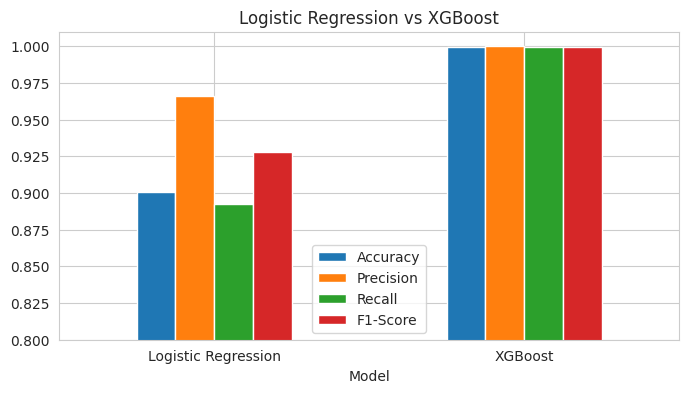

In [9]:
comparison = pd.DataFrame([res_lr, res_xgb]).set_index("Model").round(4)
display(comparison)
comparison.plot(kind="bar", figsize=(8, 4), ylim=(0.8, 1.01))
plt.title("Logistic Regression vs XGBoost"); plt.xticks(rotation=0)
plt.show()